# Estudo de Caso – Rede de Farmácias Vida+

**Disciplina:** Desenvolvimento para Ciência de Dados I – CEUB

**Aluno:** Vitor Calasans

## Parte 1 – Importação dos dados

### 1.1 Importação das bibliotecas

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid")

### 1.2 Carregamento do arquivo

In [4]:
df = pd.read_csv("data/farmacias_vida_50k.csv", encoding="utf-8-sig")

### 1.3 Cinco primeiros registros

In [5]:
df.head()

,id_venda,data_hora,filial,cidade,produto,categoria,quantidade,preco_unitario,desconto_valor,valor_liquido,forma_pagamento,classe_venda
0,VD000001,2025-06-07 03:08:41,Vida+ Ceilândia,Ceilândia,Fraldas,Infantil,1,57.56,0.00,57.56,PIX,Baixo Valor
1,VD000002,2026-01-10 01:36:32,Vida+ Norte,Brasília,Lenço umedecido,Infantil,3,37.65,5.65,107.30,Cartão de Crédito,Baixo Valor
2,VD000003,2026-10-10 17:50:57,Vida+ Sul,Brasília,Antialérgico,Medicamentos,2,45.39,4.54,86.24,Cartão de Crédito,Baixo Valor
3,VD000004,2025-03-02 00:00:47,Vida+ Centro,Brasília,Sabonete,Higiene Pessoal,1,6.73,0.00,6.73,PIX,Baixo Valor
4,VD000005,2026-06-21 17:41:05,Vida+ Taguatinga,Taguatinga,Cosmético,Beleza,1,79.16,0.00,79.16,Cartão de Débito,Baixo Valor


### 1.4 Quantidade de linhas e colunas

In [6]:
linhas, colunas = df.shape
print(f"O dataset possui {linhas} linhas e {colunas} colunas.")

O dataset possui 50000 linhas e 12 colunas.


## Parte 2 – Visualização de dados

### Gráfico 1 – Faturamento por categoria

In [7]:
faturamento_categoria = (
    df.groupby("categoria")["valor_liquido"]
      .sum()
      .sort_values(ascending=False)
)
faturamento_categoria

,valor_liquido
categoria,
Medicamentos,2544254.24
Vitaminas e Suplementos,1938235.63
Beleza,1637212.25
Infantil,1071768.85
Higiene Pessoal,536609.79
Primeiros Socorros,362593.61


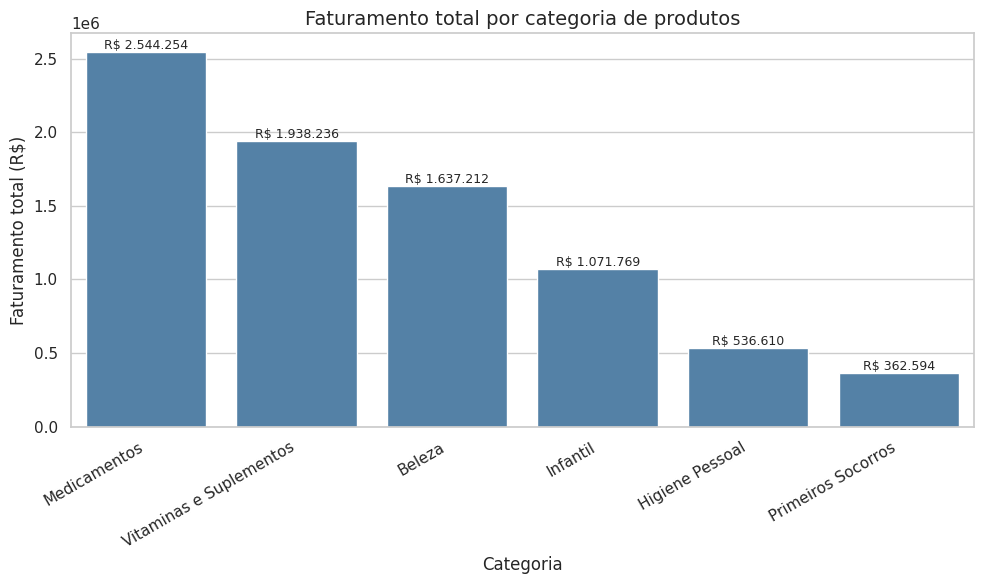

In [8]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=faturamento_categoria.index, y=faturamento_categoria.values, color="steelblue")

plt.title("Faturamento total por categoria de produtos", fontsize=14)
plt.xlabel("Categoria")
plt.ylabel("Faturamento total (R$)")
plt.xticks(rotation=30, ha="right")

for i, valor in enumerate(faturamento_categoria.values):
    ax.text(i, valor, f"R$ {valor:,.0f}".replace(",", "."), ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

### Gráfico 2 – Evolução das vendas

In [9]:
df["data_hora"] = pd.to_datetime(df["data_hora"])
df["mes"] = df["data_hora"].dt.to_period("M")

faturamento_mensal = df.groupby("mes")["valor_liquido"].sum()
faturamento_mensal.index = faturamento_mensal.index.to_timestamp()
faturamento_mensal

,valor_liquido
mes,
2025-01-01,385297.14
2025-02-01,350447.16
2025-03-01,386610.50
2025-04-01,365165.88
2025-05-01,369194.40
2025-06-01,365639.50
2025-07-01,382379.59
2025-08-01,361951.48
2025-09-01,361545.17


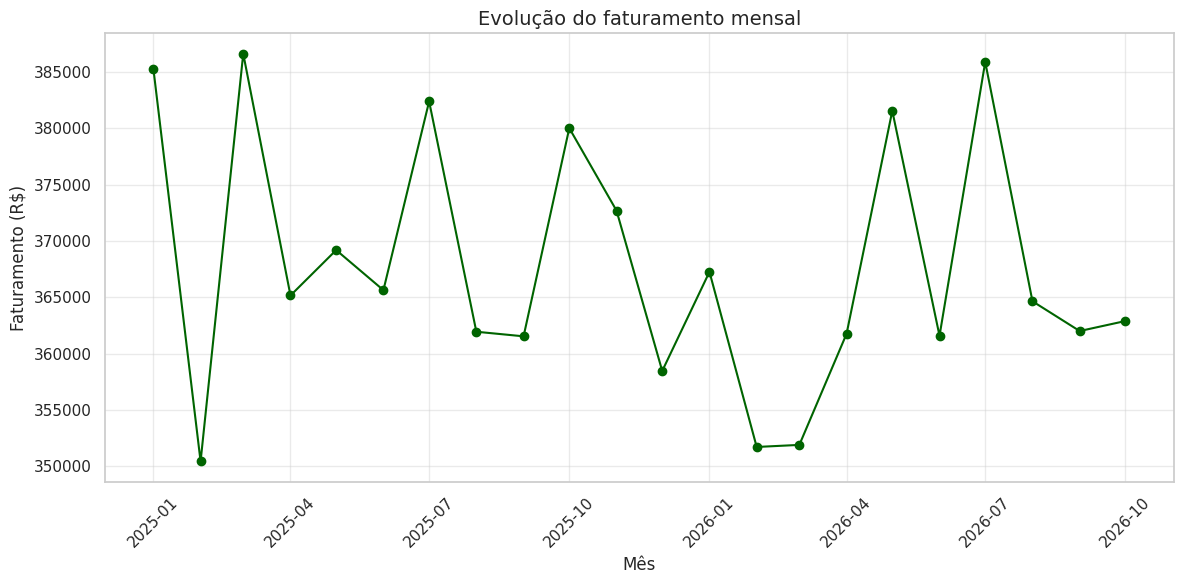

In [10]:
plt.figure(figsize=(12, 6))
plt.plot(faturamento_mensal.index, faturamento_mensal.values, marker="o", color="darkgreen")

plt.title("Evolução do faturamento mensal", fontsize=14)
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

## Parte 3 – Machine Learning: KNN

### 3.1 e 3.2 Variáveis de entrada (X) e de previsão (y)

In [11]:
X = df[["quantidade", "preco_unitario"]]
y = df["classe_venda"]

print(X.shape, y.shape)
y.value_counts()

(50000, 2) (50000,)


,count
classe_venda,
Baixo Valor,35847
Alto Valor,14153


### 3.3 Divisão em treinamento e teste

In [12]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("Treino:", X_treino.shape[0], "registros")
print("Teste: ", X_teste.shape[0], "registros")

Treino: 35000 registros
Teste:  15000 registros


### 3.4 Treinamento do modelo KNN (5 vizinhos)

In [13]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_treino, y_treino)

KNeighborsClassifier()

### 3.5 Previsões com os dados de teste

In [14]:
y_pred_knn = knn.predict(X_teste)
y_pred_knn[:10]

array(['Baixo Valor', 'Alto Valor', 'Alto Valor', 'Baixo Valor',
       'Baixo Valor', 'Baixo Valor', 'Alto Valor', 'Baixo Valor',
       'Baixo Valor', 'Alto Valor'], dtype=object)

### 3.6 Acurácia do modelo

In [15]:
acuracia_knn = accuracy_score(y_teste, y_pred_knn)
print(f"Acurácia do KNN: {acuracia_knn:.4f} ({acuracia_knn*100:.2f}%)")

Acurácia do KNN: 0.9999 (99.99%)


## Parte 4 – Machine Learning: Árvore de Decisão

### 4.1 Criação do modelo de Árvore de Decisão

In [16]:
arvore = DecisionTreeClassifier(random_state=42)
arvore

DecisionTreeClassifier(random_state=42)

### 4.2 Mesmos dados de treinamento e teste do KNN

In [17]:
print(f"Treino: {X_treino.shape[0]} registros")
print(f"Teste: {X_teste.shape[0]} registros")

Treino: 35000 registros
Teste: 15000 registros


### 4.3 Treinamento do modelo

In [18]:
arvore.fit(X_treino, y_treino)

DecisionTreeClassifier(random_state=42)

### 4.4 Previsões com os dados de teste

In [19]:
y_pred_arvore = arvore.predict(X_teste)
y_pred_arvore[:10]

array(['Baixo Valor', 'Alto Valor', 'Alto Valor', 'Baixo Valor',
       'Baixo Valor', 'Baixo Valor', 'Alto Valor', 'Baixo Valor',
       'Baixo Valor', 'Alto Valor'], dtype=object)

### 4.5 Acurácia da Árvore de Decisão

In [20]:
acuracia_arvore = accuracy_score(y_teste, y_pred_arvore)
print(f"Acurácia da Árvore de Decisão: {acuracia_arvore:.4f} ({acuracia_arvore*100:.2f}%)")

Acurácia da Árvore de Decisão: 0.9998 (99.98%)


### 4.6 Comparação dos modelos

In [21]:
comparacao = pd.DataFrame({
    "Modelo": ["KNN (k=5)", "Árvore de Decisão"],
    "Acurácia": [acuracia_knn, acuracia_arvore]
})
print(comparacao.to_string(index=False))

if acuracia_arvore > acuracia_knn:
    print("\nA Árvore de Decisão apresentou a maior acurácia.")
elif acuracia_knn > acuracia_arvore:
    print("\nO KNN apresentou a maior acurácia.")
else:
    print("\nOs dois modelos tiveram a mesma acurácia.")

           Modelo  Acurácia
        KNN (k=5)  0.999933
Árvore de Decisão  0.999800

O KNN apresentou a maior acurácia.


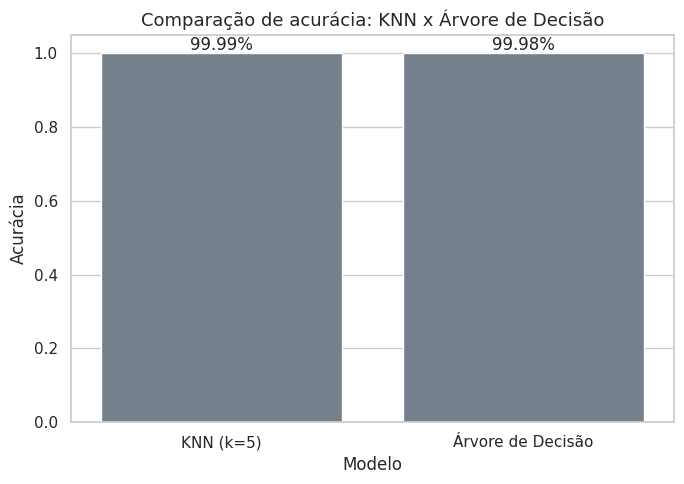

In [22]:
plt.figure(figsize=(7, 5))
ax = sns.barplot(data=comparacao, x="Modelo", y="Acurácia", color="slategray")
plt.title("Comparação de acurácia: KNN x Árvore de Decisão", fontsize=13)
plt.xlabel("Modelo")
plt.ylabel("Acurácia")
plt.ylim(0, 1.05)
for i, v in enumerate(comparacao["Acurácia"]):
    ax.text(i, v + 0.01, f"{v*100:.2f}%", ha="center")
plt.tight_layout()
plt.show()

## Parte 5 – Conclusão

**Qual algoritmo apresentou o melhor resultado?**

O **KNN (k = 5)** apresentou a maior acurácia: **99,99%**, contra **99,98%** da **Árvore de Decisão**, avaliados no mesmo conjunto de teste (15.000 vendas, 30% dos dados).

Na prática, a diferença é mínima . As duas acurácias são muito altas porque a `classe_venda` depende diretamente do valor da venda, que é calculado a partir de `quantidade × preco_unitario`. Assim, essas duas variáveis praticamente "explicam" sozinhas se a venda é de Alto ou Baixo Valor, e ambos os modelos conseguem aprender essa regra.

**Conclusão:** pelo critério da acurácia, o KNN foi o melhor modelo, mas os dois algoritmos são adequados para prever a classe das vendas da rede Vida+.